# Module 04 - AI in Finance - Build a simple Financial News Insight Application



## ITAI 2372 - Stuart Fairchild

## 🎯 Project Overview

Financial news insight - gain quick, actionable information on the financial world assisted by NLP sentiment analysis and LLM explanations.

Nothing in this project should be taken as serious financial advice. Not to be used for financial decisions.

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our Financial bot

In [2]:
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 24.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...


✅ All packages installed successfully!


[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [3]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## Data Loading and Exploration

Using Financial News Headlines Data from

https://www.kaggle.com/datasets/notlucasp/financial-news-headlines

In [4]:
# Load dataset
df = pd.read_csv('reuters_headlines.csv')

print(f"📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display first few rows
df.head()

📊 Dataset loaded successfully!
📈 Shape: (32770, 4)
📋 Columns: ['Headlines', 'Time', 'Description', 'Source']


,Headlines,Time,Description,Source
0,TikTok considers London and other locations fo...,Jul 18 2020,TikTok has been in discussions with the UK gov...,Reuters
1,Disney cuts ad spending on Facebook amid growi...,Jul 18 2020,Walt Disney has become the latest company to ...,Reuters
2,Trail of missing Wirecard executive leads to B...,Jul 18 2020,Former Wirecard chief operating officer Jan M...,Reuters
3,Twitter says attackers downloaded data from up...,Jul 18 2020,Twitter Inc said on Saturday that hackers were...,Reuters
4,U.S. Republicans seek liability protections as...,Jul 17 2020,A battle in the U.S. Congress over a new coron...,Reuters


Looking at the data, there are some issues with dates being in the description column. Will do some cleanup

In [5]:
import pandas as pd

def clean_time_and_description(row):
    time_val = str(row['Time']).strip()
    # Try to parse the 'Time' value as a date
    try:
        pd.to_datetime(time_val, errors='raise')
    except Exception:
        # If it cannot be parsed as a date, swap the description to Time and clear description
        row['Time'] = row['Description']
        row['Description'] = ""
    return row

# Apply the cleaning rule to each row
df = df.apply(clean_time_and_description, axis=1)

print("🧹 Custom cleaning rule applied!")
print(f"📊 Dataset Shape: {df.shape}")
print("\n📝 Sample of processed data:")
display(df.tail(10))

🧹 Custom cleaning rule applied!
📊 Dataset Shape: (32770, 4)

📝 Sample of processed data:


,Headlines,Time,Description,Source
32760,BMW searched by German police in emissions swoop,Mar 20 2018,BMW's headquarters were raided on Tuesday by G...,Reuters
32761,Exxon eyes Gulf of Mexico plastics plant to me...,Mar 20 2018,Exxon Mobil Corp said on Tuesday it was plann...,Reuters
32762,Kenya's ruling party says hired firm linked to...,Mar 20 2018,Kenya's ruling Jubilee party said on Tuesday i...,Reuters
32763,White House welcomes looks into reports Trump'...,Mar 20 2018,President Donald Trump wants Americans' privac...,Reuters
32764,EU demands 'unilateral' power over UK banks' a...,Mar 20 2018,European Union governments will insist on thei...,Reuters
32765,Malaysia says never hired British data firm at...,Mar 20 2018,The Malaysian government and the ruling party ...,Reuters
32766,Prosecutors search Volkswagen headquarters in ...,Mar 20 2018,German prosecutors said on Tuesday they had se...,Reuters
32767,McDonald's sets greenhouse gas reduction targets,Mar 20 2018,McDonald's Corp on Tuesday announced an approv...,Reuters
32768,Pratt & Whitney to deliver spare A320neo engin...,Mar 20 2018,Pratt & Whitney will soon begin deliveries of ...,Reuters
32769,UK will always consider ways to improve data l...,Mar 20 2018,Britain will consider any suggestions to give ...,Reuters


📊 DATASET OVERVIEW
Total articles: 32770

Missing values per column:
Headlines          0
Time               0
Description        0
Source             0
headline_length    0
word_count         0
dtype: int64

Average headline character length: 64.83
Average headline word count: 10.25


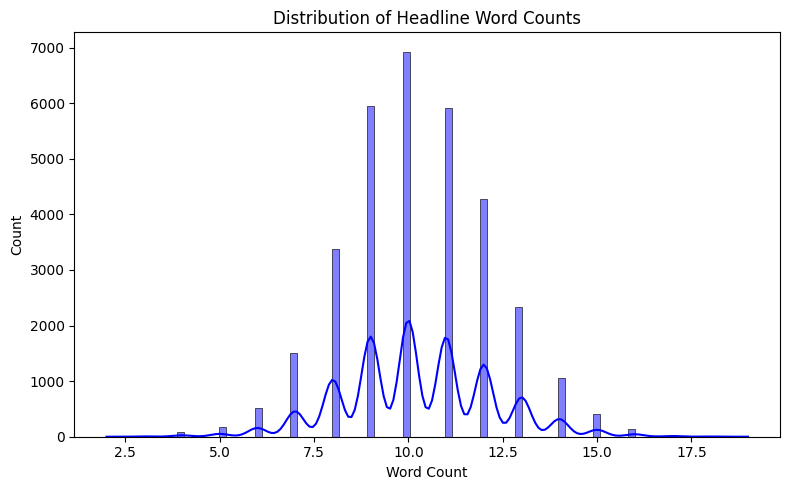

In [8]:
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")

# Check for missing values
missing_vals = df.isnull().sum()
print("\nMissing values per column:")
print(missing_vals)

# Analyze text length distribution on Headlines
df['headline_length'] = df['Headlines'].apply(lambda x: len(str(x)))
df['word_count'] = df['Headlines'].apply(lambda x: len(str(x).split()))

print(f"\nAverage headline character length: {df['headline_length'].mean():.2f}")
print(f"Average headline word count: {df['word_count'].mean():.2f}")

# Visualize word count distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['word_count'], kde=True, color='blue')
plt.title('Distribution of Headline Word Counts')
plt.xlabel('Word Count')
plt.tight_layout()
plt.show()

## Text Preprocessing Pipeline

### Advanced Text Preprocessing

* **Text Cleaning:** Remove HTML, URLs, special characters
* **Tokenization:** Split text into individual words
* **Normalization:** Convert to lowercase, handle contractions
* **Stop Word Removal:** Remove common words that don't carry meaning
* **Lemmatization:** Reduce words to their base form

In [9]:
# Ensure required NLTK resource is present
import nltk
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab')

# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nHalf-processed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Half-processed text:
apple inc announced record quarterly earnings today visit info technews


In [11]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# The dataset contains 'Headlines' and 'Description' columns.
# Let's clean and preprocess the main Headlines column.
df['full_text_clean'] = df['Headlines'].apply(clean_text)
df['full_text_processed'] = df['Headlines'].apply(preprocess_text)

# Create aliases to keep downstream code from breaking
df['full_text'] = df['Headlines']
df['title'] = df['Headlines']
df['content'] = df['Description']

# Since this dataset doesn't have an explicit 'Category' or 'ArticleId' column,
# we will assign a default category and article IDs to avoid breaking downstream steps.
df['category'] = 'business'
df['article_id'] = df.index

print("✅ Preprocessing complete!")

# Show before and after examples
print("\nBEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['Headlines'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# ANALYSIS OF PREPROCESSING
print("\nANALYSIS OF PREPROCESSING")
print("=" * 60)

# 1. Calculate average text length before and after
avg_len_before = df['Headlines'].apply(len).mean()
avg_len_after = df['full_text_processed'].apply(len).mean()
print(f"Average Character Length Before: {avg_len_before:.2f}")
print(f"Average Character Length After : {avg_len_after:.2f}")
print(f"Reduction in character count   : {((avg_len_before - avg_len_after) / avg_len_before) * 100:.2f}%")

# 2. Count unique words before and after
words_before = set()
df['Headlines'].apply(lambda x: words_before.update(str(x).lower().split()))

words_after = set()
df['full_text_processed'].apply(lambda x: words_after.update(str(x).split()))

print(f"\nUnique words (Vocabulary) Before: {len(words_before)}")
print(f"Unique words (Vocabulary) After : {len(words_after)}")
print(f"Vocabulary reduction            : {((len(words_before) - len(words_after)) / len(words_before)) * 100:.2f}%")

# 3. Identify the most common words after preprocessing
all_processed_words = []
df['full_text_processed'].apply(lambda x: all_processed_words.extend(str(x).split()))
most_common_words = Counter(all_processed_words).most_common(10)

print("\n Top 10 Most Common Words After Preprocessing:")
for word, count in most_common_words:
    print(f"  - {word}: {count} occurrences")

🧹 Preprocessing all articles...
✅ Preprocessing complete!

BEFORE AND AFTER EXAMPLES

Example 1:
Original: TikTok considers London and other locations for headquarters...
Processed: tiktok considers london location headquarters...

Example 2:
Original: Disney cuts ad spending on Facebook amid growing boycott: WSJ...
Processed: disney cut spending facebook amid growing boycott wsj...

Example 3:
Original: Trail of missing Wirecard executive leads to Belarus, Der Spiegel reports...
Processed: trail missing wirecard executive lead belarus der spiegel report...

ANALYSIS OF PREPROCESSING
Average Character Length Before: 64.83
Average Character Length After : 52.45
Reduction in character count   : 19.10%

Unique words (Vocabulary) Before: 28139
Unique words (Vocabulary) After : 16493
Vocabulary reduction            : 41.39%

 Top 10 Most Common Words After Preprocessing:
  - say: 3130 occurrences
  - china: 2920 occurrences
  - trade: 2286 occurrences
  - billion: 1784 occurrences
  - deal:

## Feature Extraction and Statistical Analysis

### TF-IDF Analysis

In [12]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (32770, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 99.84%

🔍 Sample TF-IDF features:
   abandon  abb  abbvie  abe  abroad  abu  abu dhabi  abu dhabis  abuse  \
0      0.0  0.0     0.0  0.0     0.0  0.0        0.0         0.0    0.0   
1      0.0  0.0     0.0  0.0     0.0  0.0        0.0         0.0    0.0   
2      0.0  0.0     0.0  0.0     0.0  0.0        0.0         0.0    0.0   

   accelerate  
0         0.0  
1         0.0  
2         0.0  



### Systematic Parameter Tuning for TF-IDF
To find the best parameters, we can define a parameter grid and evaluate the classification performance (using a quick model like Multinomial Naive Bayes) across different parameter combinations.


In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. Define a pipeline combining TF-IDF and a fast classifier (Naive Bayes)
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', MultinomialNB())
])

# 2. Define the parameter grid we want to experiment with
# You can add or modify parameters here based on your dataset size and constraints
param_grid = {
    'tfidf__max_features': [2500, 5000, 10000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [2, 5],
    'tfidf__max_df': [0.7, 0.8, 0.9]
}

# 3. Use GridSearchCV to search for the best combination
print("🔍 Searching for optimal TfidfVectorizer parameters...")
grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(df['full_text_processed'], df['category'])

# 4. Display results
print(f"\n🥇 Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")
print("📊 Best Parameters Selected:")
for param, value in grid_search.best_params_.items():
    print(f"  - {param.replace('tfidf__', '')}: {value}")

🔍 Searching for optimal TfidfVectorizer parameters...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

🥇 Best Cross-Validation Accuracy: 1.0000
📊 Best Parameters Selected:
  - max_df: 0.7
  - max_features: 2500
  - min_df: 2
  - ngram_range: (1, 1)


In [15]:
# Initialize TfidfVectorizer with the optimal parameters found by Grid Search
optimal_tfidf_vectorizer = TfidfVectorizer(
    max_features=2500,  # Optimal max features
    ngram_range=(1, 1),   # Optimal ngram range (unigrams)
    min_df=2,             # Optimal min document frequency
    max_df=0.7            # Optimal max document frequency (ignore terms in > 70% of docs)
)

print("🔢 Creating optimized TF-IDF features...")
tfidf_matrix = optimal_tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = optimal_tfidf_vectorizer.get_feature_names_out()

print(f"✅ Optimized TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Recreate the DataFrame for downstream analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

# Update the main reference tfidf_vectorizer so subsequent pipeline steps use it
tfidf_vectorizer = optimal_tfidf_vectorizer

print("\n🔍 Sample optimized TF-IDF features:")
display(tfidf_df.iloc[:3, :10])


🔢 Creating optimized TF-IDF features...
✅ Optimized TF-IDF matrix created!
📊 Shape: (32770, 2500)
📝 Vocabulary size: 2500
🔢 Sparsity: 99.74%

🔍 Sample optimized TF-IDF features:


,abandon,abbvie,abe,abroad,abu,abuse,accelerate,accept,access,account
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  say: 0.0211
  china: 0.0202
  trade: 0.0170
  billion: 0.0140
  deal: 0.0139
  source: 0.0129
  ceo: 0.0126
  new: 0.0126
  trump: 0.0119
  coronavirus: 0.0116


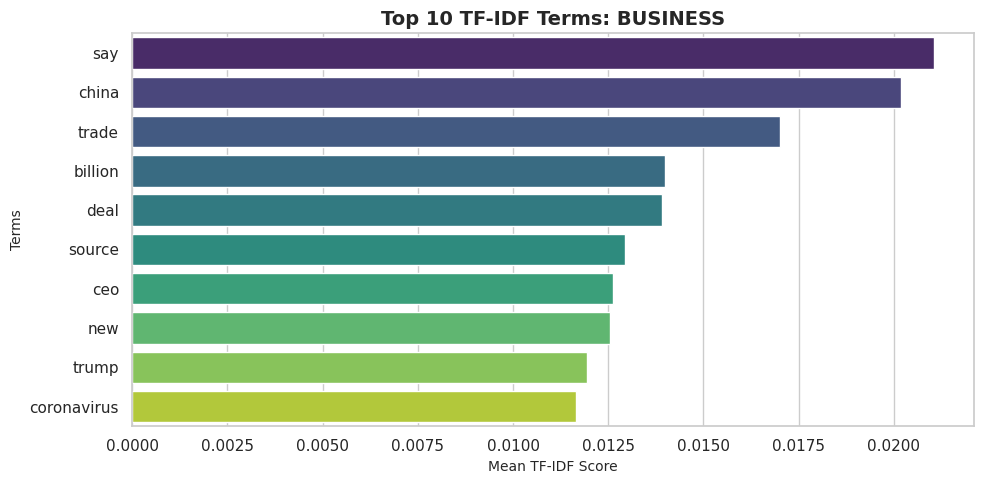

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Set style for high-quality plots
sns.set_theme(style="whitegrid")
categories = df['category'].unique()
num_categories = len(categories)

# Calculate dynamic subplot layout
cols = 2 if num_categories > 1 else 1
rows = math.ceil(num_categories / cols)

# --- 1. Bar Charts of Top Terms per Category ---
fig, axes = plt.subplots(rows, cols, figsize=(10 * cols, 5 * rows), squeeze=False)
axes_flat = axes.flatten()

for i, cat in enumerate(categories):
    top_terms = get_top_tfidf_terms(cat, n_terms=10)
    sns.barplot(
        x=top_terms.values,
        y=top_terms.index,
        ax=axes_flat[i],
        palette="viridis",
        hue=top_terms.index,
        legend=False
    )
    axes_flat[i].set_title(f"Top 10 TF-IDF Terms: {cat.upper()}", fontsize=14, fontweight='bold')
    axes_flat[i].set_xlabel("Mean TF-IDF Score", fontsize=10)
    axes_flat[i].set_ylabel("Terms", fontsize=10)

# Hide unused subplots
for j in range(i + 1, len(axes_flat)):
    axes_flat[j].axis('off')

plt.tight_layout()
plt.show()

## Part-of-Speech Analysis

### Grammatical Pattern Analysis

- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification


In [21]:
import nltk
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.tag import pos_tag
import pandas as pd

# Ensure required NLTK resources are downloaded
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('punkt', quiet=True)

def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text
    """
    if not text or pd.isna(text):
        return {}

    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}
    return pos_proportions

print("🏷️ Analyzing POS patterns...")

pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

print("\n📝 Sample POS analysis:")
display(pos_df.head())

🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 44 different POS tags

📝 Sample POS analysis:


,NNP,NNS,CC,JJ,IN,category,article_id,NN,VBG,:,...,EX,``,WP,WDT,(,),UH,SYM,#,WP$
0,0.250000,0.375000,0.125,0.125000,0.125000,business,0,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.181818,0.090909,0.000,0.000000,0.181818,business,1,0.363636,0.090909,0.090909,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.333333,0.083333,0.000,0.000000,0.083333,business,2,0.166667,0.083333,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.090909,0.272727,0.000,0.090909,0.181818,business,3,0.000000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.100000,0.200000,0.000,0.000000,0.100000,business,4,0.400000,0.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Syntax Parsing and Semantic Analysis

### Understanding Sentence Structure

- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text


In [24]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 1
  Tokens: 8
  Noun phrases: ['tiktok', 'london', 'other locations']...
  Subjects: ['tiktok']...
  Objects: ['london', 'headquarters']...

📰 Article 2 (business):
  Sentences: 1
  Tokens: 11
  Noun phrases: ['disney', 'ad spending', 'facebook']...
  Subjects: ['disney']...
  Objects: ['spending', 'facebook', 'boycott']...

📰 Article 3 (business):
  Sentences: 1
  Tokens: 12
  Noun phrases: ['trail', 'missing wirecard executive', 'belarus']...
  Subjects: ['trail', 'spiegel']...
  Objects: ['executive', 'belarus']...

📰 Article 4 (business):
  Sentences: 1
  Tokens: 13
  Noun phrases: ['twitter', 'attackers', 'data']...
  Subjects: ['twitter', 'attackers']...
  Objects: ['data', 'accounts']...

📰 Article 5 (business):
  Sentences: 1
  Tokens: 10
  Noun phrases: ['u.s. republicans', 'liability protections', 'coronavirus aid battle']...
  Subjects: ['republicans', 'battle']...
  Objec

## Sentiment and Emotion Analysis

### Understanding Emotional Tone

- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone


In [47]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer safely for the Reuters Headlines dataset.
    Ensures the 'sentiment_label' is guaranteed to be present and maps the compound score to a [0, 1] scale.
    """
    if not text or pd.isna(text):
        return {'compound': 0.5, 'pos': 0.0, 'neu': 1.0, 'neg': 0.0, 'sentiment_label': 'neutral'}

    scores = sia.polarity_scores(str(text))

    # Shift compound score from [-1, 1] to [0, 1]
    scaled_compound = (scores['compound'] + 1.0) / 2.0
    scores['compound'] = scaled_compound

    # Explicit threshold mapping on the 0-1 scaled score
    # Standard neutral was [-0.05, 0.05], which maps to [0.475, 0.525]
    if scaled_compound >= 0.525:
        scores['sentiment_label'] = 'positive'
    elif scaled_compound <= 0.475:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

print("😊 Running sentiment analysis pipeline over Reuters dataset with scaled sentiment compound [0, 1]...")

sentiment_results = []
for idx, row in df.iterrows():
    # We calculate sentiment on Title (Headlines) and Content (Description representation)
    title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text_processed'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'time': row['Time'],
        'title_sentiment': title_sentiment['compound'],
        'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

sentiment_df = pd.DataFrame(sentiment_results)
print("✅ Sentiment analysis completed successfully with compound scores on [0, 1] scale!")
print(f"📊 Total articles analyzed: {len(sentiment_df)}")
display(sentiment_df[['category', 'full_sentiment', 'full_label', 'time']].head())

😊 Running sentiment analysis pipeline over Reuters dataset with scaled sentiment compound [0, 1]...
✅ Sentiment analysis completed successfully with compound scores on [0, 1] scale!
📊 Total articles analyzed: 32770


,category,full_sentiment,full_label,time
0,business,0.50000,neutral,Jul 18 2020
1,business,0.29905,negative,Jul 18 2020
2,business,0.35200,negative,Jul 18 2020
3,business,0.21405,negative,Jul 18 2020
4,business,0.17570,negative,Jul 17 2020


⏳ Processing temporal fields...
📊 SENTIMENT & TEMPORAL TREND SUMMARY


full_sentiment                         pos_score neg_score
                   mean     std     min     max      mean      mean
category                                                           
business         0.4983  0.1689  0.0441  0.9623     0.116    0.1151

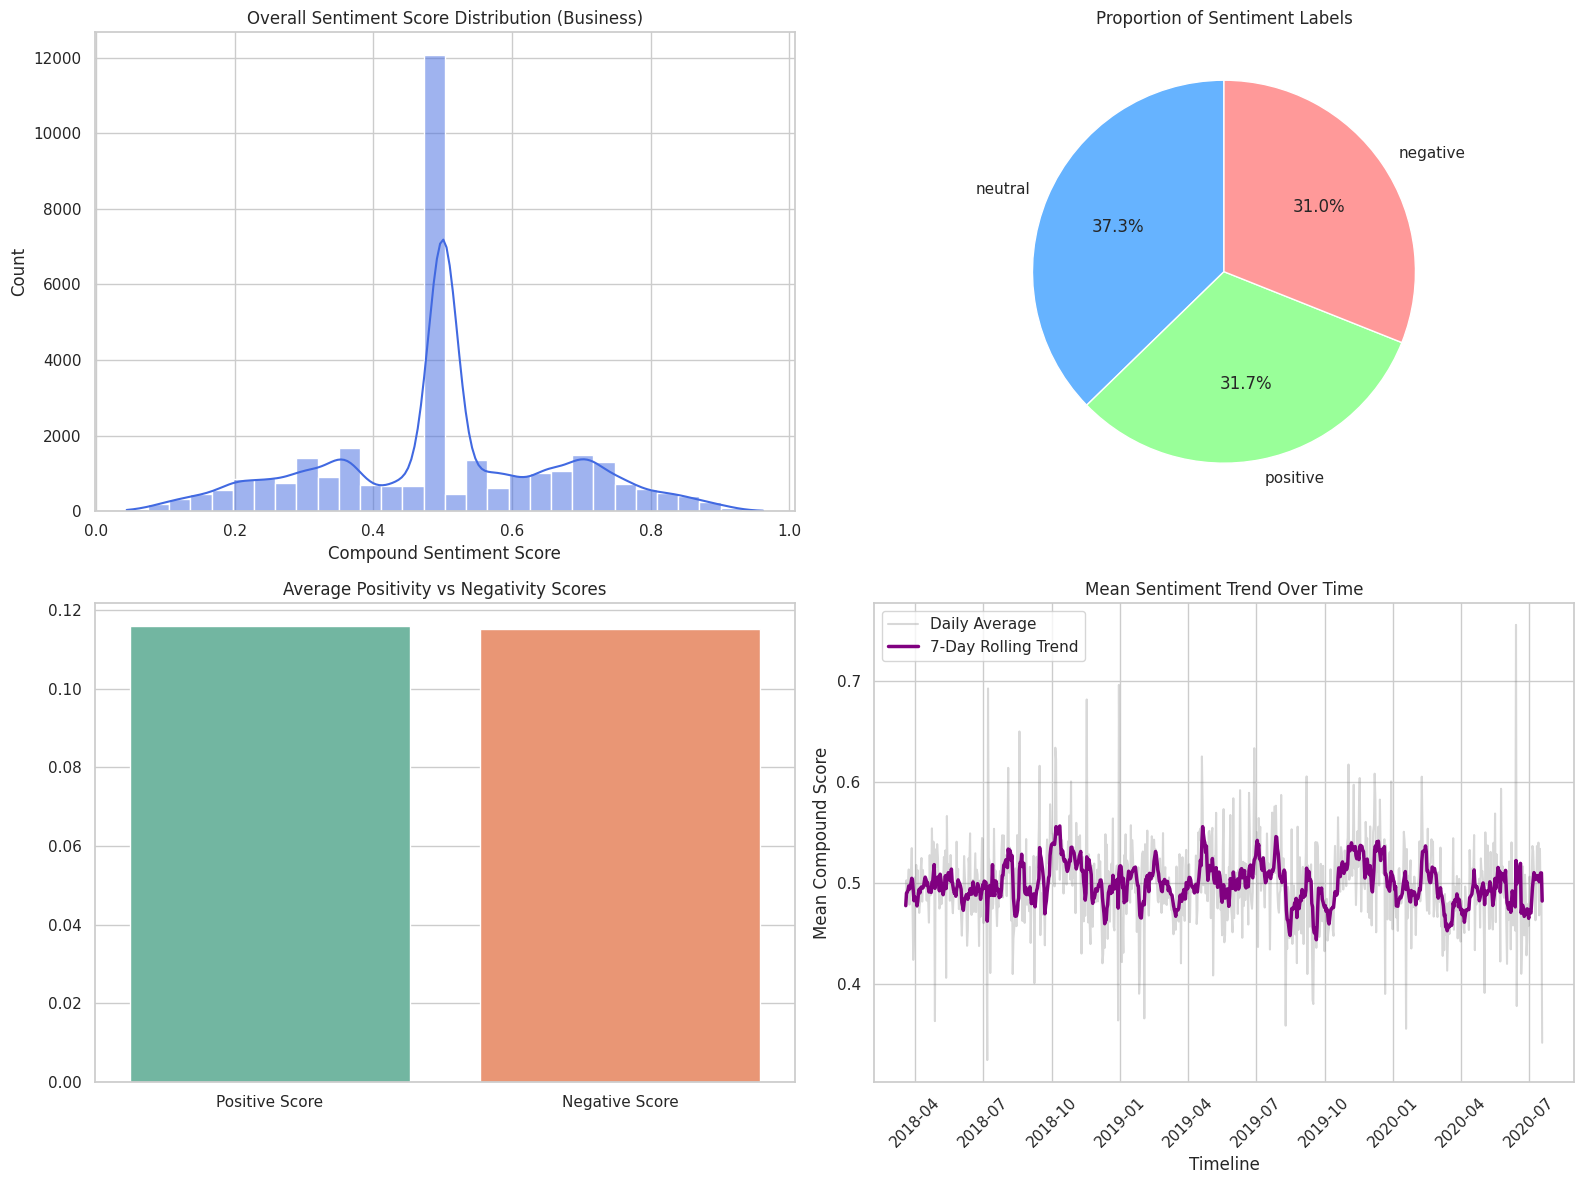

In [48]:
# Clean and format dates to track temporal sentiment volatility and trends
print("⏳ Processing temporal fields...")
sentiment_df['parsed_date'] = pd.to_datetime(sentiment_df['time'], errors='coerce')

# Group and calculate mean compound score over time
temporal_sentiment = sentiment_df.dropna(subset=['parsed_date']).groupby('parsed_date')['full_sentiment'].mean().reset_index()

# Sort chronologically
temporal_sentiment = temporal_sentiment.sort_values(by='parsed_date')

# Calculate a 7-day rolling window for a smoother visualization trend
temporal_sentiment['rolling_sentiment'] = temporal_sentiment['full_sentiment'].rolling(window=7, min_periods=1).mean()

print("📊 SENTIMENT & TEMPORAL TREND SUMMARY")
print("=" * 50)

# Display Category Metrics
sent_metrics = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neg_score': 'mean'
}).round(4)
display(sent_metrics)

# Set up plots optimized for single category dataset
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribution of Compound Sentiment
sns.histplot(data=sentiment_df, x='full_sentiment', kde=True, bins=30, color='royalblue', ax=axes[0,0])
axes[0,0].set_title('Overall Sentiment Score Distribution (Business)')
axes[0,0].set_xlabel('Compound Sentiment Score')

# 2. Sentiment Label Proportion
sentiment_counts = sentiment_df['full_label'].value_counts()
axes[0,1].pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', colors=['#66b3ff','#99ff99','#ff9999'], startangle=90)
axes[0,1].set_title('Proportion of Sentiment Labels')

# 3. Positivity vs Negativity
sns.barplot(data=sentiment_df[['pos_score', 'neg_score']], errorbar=None, ax=axes[1,0], palette='Set2')
axes[1,0].set_title('Average Positivity vs Negativity Scores')
axes[1,0].set_xticklabels(['Positive Score', 'Negative Score'])

# 4. Temporal Trends over Time with Rolling Window
if not temporal_sentiment.empty:
    sns.lineplot(data=temporal_sentiment, x='parsed_date', y='full_sentiment', alpha=0.3, label='Daily Average', color='gray', ax=axes[1,1])
    sns.lineplot(data=temporal_sentiment, x='parsed_date', y='rolling_sentiment', label='7-Day Rolling Trend', color='purple', linewidth=2.5, ax=axes[1,1])
    axes[1,1].set_title('Mean Sentiment Trend Over Time')
    axes[1,1].set_xlabel('Timeline')
    axes[1,1].set_ylabel('Mean Compound Score')
    axes[1,1].tick_params(axis='x', rotation=45)
    axes[1,1].legend()
else:
    axes[1,1].text(0.5, 0.5, 'No temporal data available to display.', ha='center', va='center', transform=axes[1,1].transAxes)

plt.tight_layout()
plt.show()

## Named Entity Recognition

### Extracting Facts from News

- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants


In [49]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 66697
📰 Articles processed: 32770

🏷️ Entity types found: ['ORG' 'GPE' 'PERSON' 'CARDINAL' 'NORP' 'WORK_OF_ART' 'DATE' 'PRODUCT'
 'FAC' 'MONEY' 'TIME' 'ORDINAL' 'PERCENT' 'LOC' 'QUANTITY' 'LAW' 'EVENT'
 'LANGUAGE']

📝 Sample entities:
          text     label  category
0       TikTok       ORG  business
1       London       GPE  business
2          WSJ       ORG  business
3     Wirecard       ORG  business
4      Belarus       GPE  business
5  Der Spiegel    PERSON  business
6      Twitter    PERSON  business
7  up to eight  CARDINAL  business
8         U.S.       GPE  business
9  Republicans      NORP  business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
ORG            26913
GPE            17446
PERSON          5223
DATE            4818
NORP            3741
CARDINAL        2739
MONEY           2674
PERCENT          852
LOC              748
PRODUCT          720
ORDINAL          424
FAC              141
TIME              74
WORK_OF_ART       63
EVENT             43
QUANTITY          39
LAW               35
LANGUAGE           4
Name: count, dtype: int64

📰 Entity types by news category:
label     CARDINAL  DATE  EVENT  FAC    GPE  LANGUAGE  LAW  LOC  MONEY  NORP  \
category                                                                       
business      2739  4818     43  141  17446         4   35  748   2674  3741   

label     ORDINAL    ORG  PERCENT  PERSON  PRODUCT  QUANTITY  TIME  \
category                                                             
business      424  26913      852    5223      720        39    74   

label     WORK_OF_ART  
category               
bu

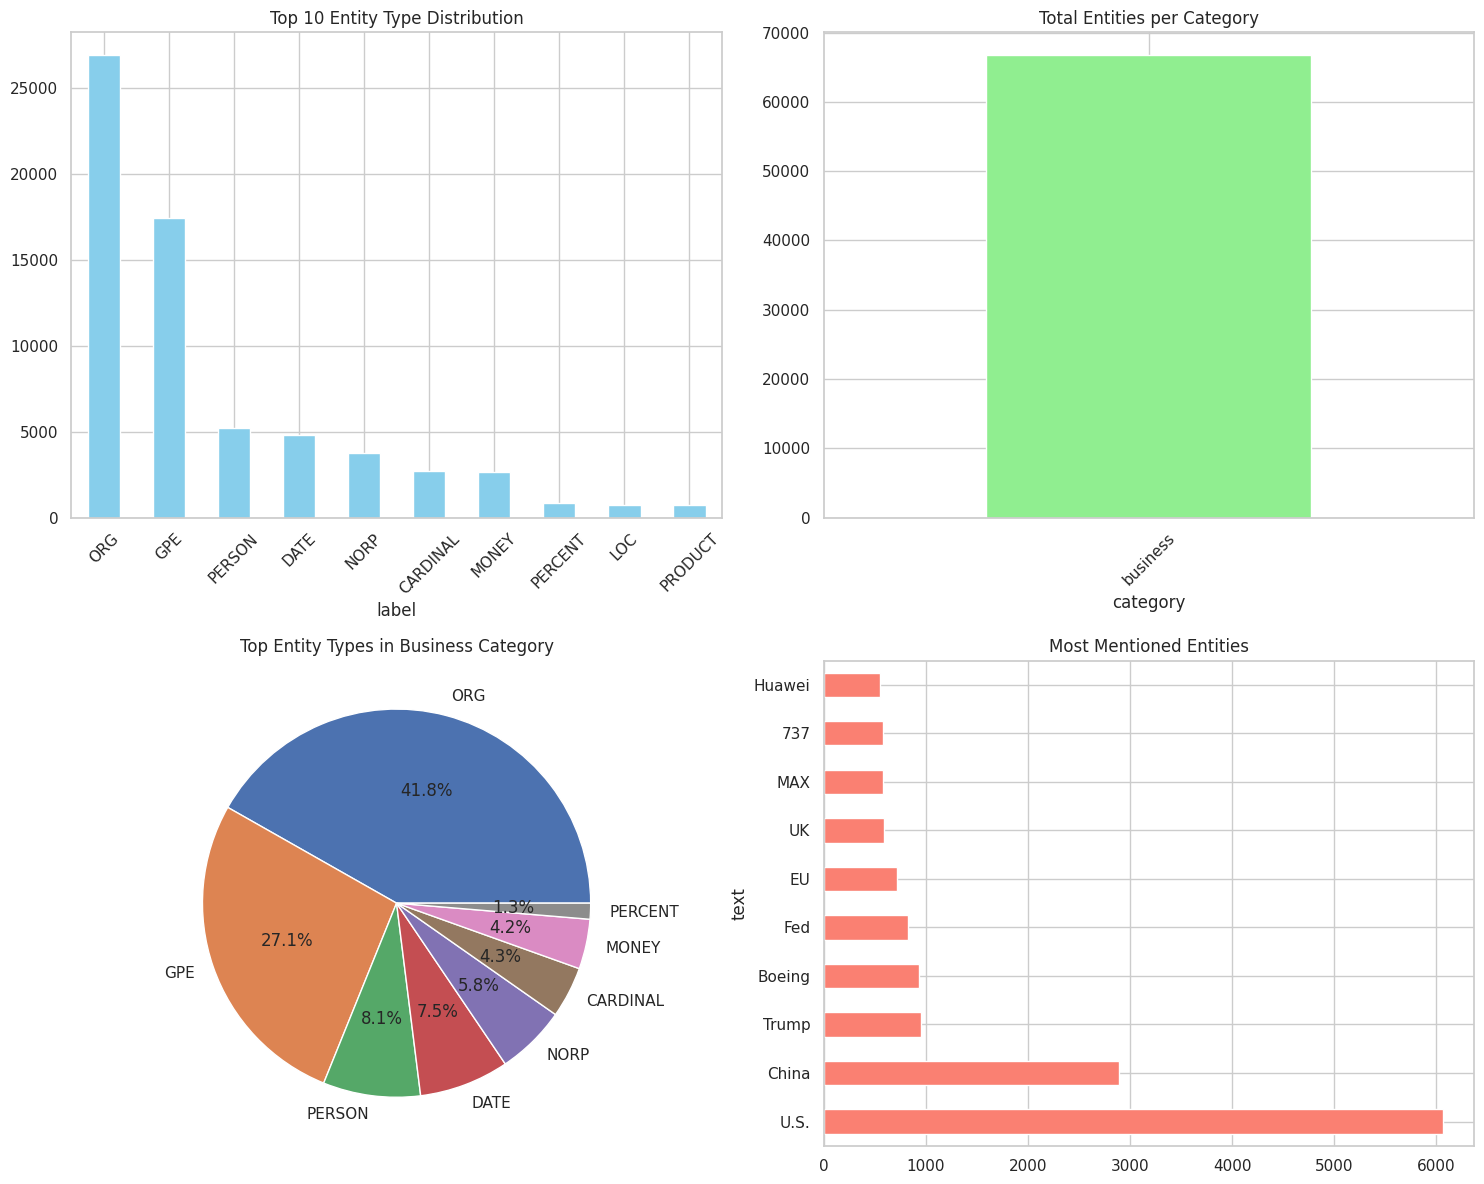

In [38]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations using explicit 2x2 grid layout
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.head(10).plot(kind='bar', ax=axes[0,0], color='skyblue')
    axes[0,0].set_title('Top 10 Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Total entities per category (safely computed for single-category or multi-category data)
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1], color='lightgreen')
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap or placeholder
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        # Visual representation of top entity labels for the single category
        entities_df[entities_df['category'] == 'business']['label'].value_counts().head(8).plot(kind='pie', ax=axes[1,0], autopct='%1.1f%%')
        axes[1,0].set_title('Top Entity Types in Business Category')
        axes[1,0].set_ylabel('')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1], color='salmon')
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [41]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining NLP analyses

    💡 TIP: This function should combine:
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")


📊 Generating comprehensive analysis...

📊 DATASET OVERVIEW:
  Total Articles: 32770
  Categories: business
  Average Article Length: 65 characters
  Average Words per Article: 10 words

😊 SENTIMENT INSIGHTS:
  Most Positive Category: business
  Most Negative Category: business
  Overall Sentiment: -0.0035

🔍 ENTITY INSIGHTS:
  Total Entities: 66697
  Unique Entities: 9819
  Entity Types: ORG, GPE, PERSON, CARDINAL, NORP, WORK_OF_ART, DATE, PRODUCT, FAC, MONEY, TIME, ORDINAL, PERCENT, LOC, QUANTITY, LAW, EVENT, LANGUAGE


## Final System Integration

### Building the Complete Pipeline

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. ~~**Classification:** Predict article category~~
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence


In [44]:
class FinancialIntelligenceSystem:
    """
    Financial Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, vectorizer, sentiment_analyzer):
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Extract entities
        entities = self.extract_entities(full_text)

        # Step 3: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 4: Generate insights
        insights = self.generate_insights(entities, sentiment)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, entities, sentiment):
        """Generate actionable insights"""
        insights = []

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
finbot = FinancialIntelligenceSystem(
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("Financial Intelligence System initialized!")
print("✅ Ready to process new articles")

Financial Intelligence System initialized!
✅ Ready to process new articles


In [51]:
# Test the complete system with new articles
print("TESTING FINANCIAL INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = finbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 Financial Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

TESTING FINANCIAL INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

😊 Sentiment: positive (score: 0.830)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  😊 Positive sentiment detected (0.830)
  🔍 Found 8 entities of 5 types
  🎯 Key entities: Microsoft Acquires, Microsoft Corporation, Satya Nadella

📰 TEST ARTICLE 2
----------------------------------------
📰 Title: Lakers Win Championship in Overtime Thr

In [52]:
# Load the test dataset from our already loaded DataFrame instead of a missing local CSV
print(f"📊 Using active Reuters Dataset. Shape: {df.shape}")

# Select 10 representative articles from our dataset
sample_test = df.head(10)

print("🧪 Running Complete Pipeline on 10 Sample Articles...\n")
for i, row in sample_test.iterrows():
    text_content = str(row['Description'] if row['Description'] else row['Headlines'])
    title_proxy = str(row['Headlines'])[:60] + '...'

    # Process the article using the initialized finbot system
    result = finbot.process_article(title_proxy, text_content)

    print(f"📰 ARTICLE {i+1}:")
    print(f"  Title Proxy: {result['title']}")
    print(f"  Sentiment Label: {result['sentiment']['sentiment_label']} (Score: {result['sentiment']['compound']:.3f})")

    # Display top 5 unique entities found
    unique_ents = list({ent['text']: ent for ent in result['entities']}.values())
    if unique_ents:
        ent_str = ", ".join([f"{e['text']} ({e['label']})" for e in unique_ents[:5]])
        print(f"  Key Entities: {ent_str}")
    else:
        print("  Key Entities: None found")
    print("-" * 50)

📊 Using active Reuters Dataset. Shape: (32770, 13)
🧪 Running Complete Pipeline on 10 Sample Articles...

📰 ARTICLE 1:
  Title Proxy: TikTok considers London and other locations for headquarters...
  Sentiment Label: neutral (Score: 0.513)
  Key Entities: TikTok (ORG), London (GPE), UK (GPE), the past few months (DATE), Chinese (NORP)
--------------------------------------------------
📰 ARTICLE 2:
  Title Proxy: Disney cuts ad spending on Facebook amid growing boycott: WS...
  Sentiment Label: negative (Score: 0.053)
  Key Entities: Walt Disney (PERSON), Facebook Inc (ORG), the Wall Street Journal (ORG), Saturday (DATE)
--------------------------------------------------
📰 ARTICLE 3:
  Title Proxy: Trail of missing Wirecard executive leads to Belarus, Der Sp...
  Sentiment Label: negative (Score: 0.176)
  Key Entities: Wirecard (PERSON), Belarus (GPE), Der Sp (PERSON), Jan Marsalek (PERSON), Minsk (GPE)
--------------------------------------------------
📰 ARTICLE 4:
  Title Proxy: Twitte

### 🐳 Packaging the Pipeline for Docker with a Web Interface

To make our `FinancialIntelligenceSystem` accessible as a web application, we will package it with:
* **FastAPI** as the robust backend API (handles web scraping from links, parsing, and pipeline calculations).
* **Streamlit** as a clean, interactive user interface allowing users to submit URLs and instantly visualize entities, sentiment on a `[0, 1]` scale, and insights.

In [53]:
%%writefile app.py
import os
import re
import spacy
import requests
from bs4 import BeautifulSoup
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
import nltk

# Ensure resources are downloaded
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('vader_lexicon', quiet=True)

# Initialize dependencies
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
sia = SentimentIntensityAnalyzer()

try:
    nlp = spacy.load('en_core_web_sm')
except OSError:
    # Fallback to download spacy model if not present
    os.system('python -m spacy download en_core_web_sm')
    nlp = spacy.load('en_core_web_sm')

app = FastAPI(title="Financial News Intelligence API", version="1.0.0")

class LinkRequest(BaseModel):
    url: str

def clean_and_preprocess(text):
    if not text:
        return ""
    text = text.lower()
    text = re.sub(r'<[^>]+>', '', text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    tokens = word_tokenize(text)
    tokens = [token for token in tokens if token not in stop_words]
    tokens = [lemmatizer.lemmatize(token) for token in tokens]
    tokens = [token for token in tokens if len(token) > 2]
    return ' '.join(tokens)

@app.post("/analyze")
def analyze_link(request: LinkRequest):
    try:
        # Scrape article from link
        headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        response = requests.get(request.url, headers=headers, timeout=10)
        if response.status_code != 200:
            raise HTTPException(status_code=400, detail="Could not retrieve content from URL")

        soup = BeautifulSoup(response.text, 'html.parser')

        # Extract title and body text
        title = soup.title.string if soup.title else "Extracted Article Link"

        # Remove script and style elements
        for script in soup(["script", "style"]):
            script.decompose()

        paragraphs = soup.find_all('p')
        content = ' '.join([p.get_text() for p in paragraphs])

        if len(content.strip()) < 10:
            raise HTTPException(status_code=400, detail="Webpage has insufficient extractable text")

        full_text = f"{title} {content}"

        # 1. Scaled Sentiment compound score [0, 1]
        scores = sia.polarity_scores(full_text)
        scaled_compound = (scores['compound'] + 1.0) / 2.0

        if scaled_compound >= 0.525:
            label = 'positive'
        elif scaled_compound <= 0.475:
            label = 'negative'
        else:
            label = 'neutral'

        # 2. NER extraction
        doc = nlp(full_text[:100000]) # Protect memory limit
        entities = []
        for ent in doc.ents:
            entities.append({
                'text': ent.text,
                'label': ent.label_,
                'description': spacy.explain(ent.label_)
            })

        # Keep unique entities
        unique_entities = list({e['text']: e for e in entities}.values())

        # 3. Generate insights
        insights = []
        insights.append(f"Sentiment Score: {scaled_compound:.3f} ({label.upper()})")
        if unique_entities:
            insights.append(f"Extracted {len(unique_entities)} distinct names, places, and financial entities.")
            key_orgs = [e['text'] for e in unique_entities if e['label'] == 'ORG'][:3]
            if key_orgs:
                insights.append(f"Key Organizations detected: {', '.join(key_orgs)}")

        return {
            "title": title.strip(),
            "sentiment": {
                "compound": scaled_compound,
                "label": label,
                "details": scores
            },
            "entities": unique_entities[:15],
            "insights": insights
        }
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

Writing app.py


# Deploy

In [69]:
%%writefile docker-compose.yml
version: '3.8'

services:
  ollama:
    image: ollama/ollama:latest
    container_name: finbot-ollama
    volumes:
      - ollama_storage:/root/.ollama
    ports:
      - "11434:11434"

  backend:
    build: .
    container_name: finbot-backend
    ports:
      - "8000:8000"
    environment:
      - OLLAMA_HOST=http://ollama:11434
    command: uvicorn finbot_backend:app --host 0.0.0.0 --port 8000
    depends_on:
      - ollama

  frontend:
    build: .
    container_name: finbot-frontend
    ports:
      - "8501:8501"
    environment:
      - BACKEND_URL=http://backend:8000
    command: streamlit run frontend.py --server.port 8501 --server.address 0.0.0.0
    depends_on:
      - backend

volumes:
  ollama_storage:

Overwriting docker-compose.yml


In [70]:
%%writefile finbot_backend.py
import os
import re
import spacy
import requests
from bs4 import BeautifulSoup
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
import nltk

# Ensure resources are downloaded
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('vader_lexicon', quiet=True)

# Initialize dependencies
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
sia = SentimentIntensityAnalyzer()

try:
    nlp = spacy.load('en_core_web_sm')
except OSError:
    os.system('python -m spacy download en_core_web_sm')
    nlp = spacy.load('en_core_web_sm')

app = FastAPI(title="Financial News Intelligence API with Ollama", version="2.0.0")

class LinkRequest(BaseModel):
    url: str

def clean_and_preprocess(text):
    if not text:
        return ""
    text = text.lower()
    text = re.sub(r'<[^>]+>', '', text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def get_ollama_insight(title, content):
    ollama_host = os.getenv("OLLAMA_HOST", "http://localhost:11434")
    model_name = "tinyllama"

    prompt = f"""Explain this financial news article to a layman who has no prior knowledge of finance, business, or complex stock market terminology. Keep the language highly accessible, use simple analogies if helpful, and summarize the core message in 3 simple bullet points:

    TITLE: {title}
    CONTENT: {content[:3000]}
    """

    try:
        requests.post(f"{ollama_host}/api/pull", json={"name": model_name}, timeout=5)
        response = requests.post(
            f"{ollama_host}/api/generate",
            json={
                "model": model_name,
                "prompt": prompt,
                "stream": False
            },
            timeout=25
        )
        if response.status_code == 200:
            return response.json().get("response", "No summary generated.")
    except Exception as e:
        return f"Ollama analysis unavailable ({str(e)}). Ensure Ollama is running and has downloaded the '{model_name}' model."
    return "Ollama model was unable to generate a response."

@app.post("/analyze")
def analyze_link(request: LinkRequest):
    try:
        headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        response = requests.get(request.url, headers=headers, timeout=10)
        if response.status_code != 200:
            raise HTTPException(status_code=400, detail="Could not retrieve content from URL")

        soup = BeautifulSoup(response.text, 'html.parser')
        title = soup.title.string if soup.title else "Extracted Article Link"

        for script in soup(["script", "style"]):
            script.decompose()

        paragraphs = soup.find_all('p')
        content = ' '.join([p.get_text() for p in paragraphs])

        if len(content.strip()) < 10:
            raise HTTPException(status_code=400, detail="Webpage has insufficient extractable text")

        full_text = f"{title} {content}"

        # 1. Scaled Sentiment compound score [0, 1]
        scores = sia.polarity_scores(full_text)
        scaled_compound = (scores['compound'] + 1.0) / 2.0

        if scaled_compound >= 0.525:
            label = 'positive'
        elif scaled_compound <= 0.475:
            label = 'negative'
        else:
            label = 'neutral'

        # 2. NER extraction
        doc = nlp(full_text[:100000])
        entities = []
        for ent in doc.ents:
            entities.append({
                'text': ent.text,
                'label': ent.label_,
                'description': spacy.explain(ent.label_)
            })

        unique_entities = list({e['text']: e for e in entities}.values())

        # 3. Generate traditional rule-based insights
        insights = []
        insights.append(f"Sentiment Score: {scaled_compound:.3f} ({label.upper()})")
        if unique_entities:
            insights.append(f"Extracted {len(unique_entities)} distinct financial entities.")
            key_orgs = [e['text'] for e in unique_entities if e['label'] == 'ORG'][:3]
            if key_orgs:
                insights.append(f"Key Organizations: {', '.join(key_orgs)}")

        # 4. Generate local Ollama LLM insights
        ai_briefing = get_ollama_insight(title, content)

        return {
            "title": title.strip(),
            "sentiment": {
                "compound": scaled_compound,
                "label": label,
                "details": scores
            },
            "entities": unique_entities[:15],
            "insights": insights,
            "ai_briefing": ai_briefing
        }
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

Writing finbot_backend.py


In [65]:
%%writefile frontend.py
import streamlit as st
import requests
import os

st.set_page_config(page_title="FinBot Web Insights + Ollama", layout="wide")
st.title("📈 Financial News Link Analyzer with Local LLM")
st.write("Paste any financial article link from the web to run sentiment scaling, entity recognition, and local Ollama-powered contextual summaries.")

backend_host = os.getenv("BACKEND_URL", "http://localhost:8000")
api_url = f"{backend_host}/analyze"

url_input = st.text_input("Article URL:", placeholder="https://www.reuters.com/business/...")

if st.button("Analyze Article"):
    if not url_input:
        st.warning("Please enter a valid URL first.")
    else:
        with st.spinner("Running full pipeline (Scraping -> VADER Sentiment -> SpaCy NER -> Local Ollama LLM Insight)... This may take up to 20 seconds."):
            try:
                response = requests.post(api_url, json={"url": url_input}, timeout=45)
                if response.status_code == 200:
                    data = response.json()

                    st.success("Analysis complete!")
                    st.subheader(f"📰 {data['title']}")

                    # Main Content Partitioning
                    col1, col2 = st.columns(2)

                    with col1:
                        st.write("### 🤖 Local Ollama Smart Briefing")
                        st.write(data.get('ai_briefing', 'No AI summary available.'))

                        st.write("### 😊 Sentiment Matrix")
                        compound = data['sentiment']['compound']
                        label = data['sentiment']['label'].upper()

                        st.metric(label=f"Scaled Compound Sentiment ({label})", value=f"{compound:.3f}")
                        st.progress(compound)
                        st.info("*Note: Sentiment compound score is normalized on a scale from 0.0 (Extremely Bearish) to 1.0 (Extremely Bullish).* ")

                    with col2:
                        st.write("### 💡 Actionable Insights")
                        for insight in data['insights']:
                            st.write(f"- {insight}")

                        st.write("### 🔍 Key Extracted Entities")
                        if data['entities']:
                            for ent in data['entities']:
                                st.write(f"🔹 **{ent['text']}** ({ent['label']}) — *{ent['description']}*")
                        else:
                            st.write("No key entities detected in this article.")
                else:
                    st.error(f"Error: {response.json().get('detail', 'Unable to analyze the website link.')}")
            except Exception as e:
                st.error(f"Could not reach backend API at {api_url}. Please ensure your services are fully running via docker-compose.")

Overwriting frontend.py


### 🛠️ How to run locally with Docker:

1. Save the generated files into a unified directory (`app.py`, `frontend.py`, `requirements.txt`, `Dockerfile`).
2. Build the Docker image:
   ```bash
   docker build -t financial-news-bot .
   ```
3. Start the container:
   ```bash
   docker run -p 8000:8000 -p 8501:8501 financial-news-bot
   ```
4. Access the web interface in your browser at **`http://localhost:8501`**!

In [66]:
%%writefile README.md
# 📈 FinBot Intelligence System with Local LLM (Ollama)

A fully containerized pipeline built with **FastAPI**, **Streamlit**, and **Ollama** that pulls financial web articles, calculates sentiment on a `[0, 1]` scale, performs Named Entity Recognition (NER), and delivers AI summaries running on a local, secure LLM.

## 🚀 Features

* **🌐 Web Article Scraping**: Instantly extracts and parses text contents from any public financial URL.
* **😊 Sentiment Normalization**: Scales VADER polarity metrics to a `[0, 1]` range (extremely bearish to bullish).
* **🔍 Entity Recognition**: Identifies companies, dates, names, and organizations using SpaCy.
* **🤖 Local LLM Summaries**: Uses **Ollama** (`tinyllama`) running completely offline in your local environment to generate bulleted briefings.
* **🐳 Production Ready**: Fully configured using Docker Compose with persistent model storage volume caching.

## 🛠️ How to Deploy Locally with Docker Compose

1. Ensure you have Docker and Docker Compose installed.
2. Spin up the container cluster (Frontend, Backend, and Ollama services):
   ```bash
   docker compose up --build -d
   ```
3. Upon first startup, the backend automatically instructs Ollama to download and pull the `tinyllama` model.
4. Open your browser and view the interactive UI dashboard at **`http://localhost:8501`**!
5. Shut down the microservice stack:
   ```bash
   docker compose down
   ```

## 📁 Code Architecture

* `app.py`: FastAPI server containing scraper rules, SpaCy entity recognition, and Ollama client routines.
* `frontend.py`: Streamlit-based interactive web interface with dual-column layout.
* `docker-compose.yml`: Multi-container orchestrator creating a shared virtual network and persistent storage volumes.

Overwriting README.md
